# Tugas Bagian A: Dasar Data dan Pemahaman Granularitas
**Dataset:** `customer_behavior_phase1.csv` (10.000 baris transaksi, 19 kolom variabel)

Notebook ini berisi pembuktian kuantitatif **Bagian A.2 (Audit Kualitas Data)** serta verifikasi **Bagian A.1** dan **Bagian A.3**, melengkapi 2 workbook Excel (`TugasBagianA_Kelompok.xlsx` dan `TugasBagianA_Bersih.xlsx`).

In [1]:
# Library analisis data dan visualisasi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pembacaan dataset
df = pd.read_csv('customer_behavior_phase1.csv')
df.head()

,Transaction_ID,Customer_ID,Age,Gender,City,Region,Membership_Level,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percentage,Purchase_Amount,Payment_Method,Store_Type,Purchase_Date,Purchase_Hour,Purchase_Day,Customer_Satisfaction
0,TRX-000001,CUST-02118,35,Female,Jakarta,Jabodetabek,Gold,Groceries,Assorted Snack Box,5,104000.0,0.0,520000.0,QRIS,Online App,2026-01-01,3,Thursday,3
1,TRX-000002,CUST-03099,26,Male,Yogyakarta,Central Java,Basic,Home & Living,Air Purifier Mini,2,304000.0,20.0,486400.0,Credit Card,Online App,2026-01-01,5,Thursday,1
2,TRX-000003,CUST-01259,37,Female,Sidoarjo,East Java,Basic,Fashion,Casual Chino Pants,2,427000.0,10.0,768600.0,E-Wallet,Online App,2026-01-01,8,Thursday,1
3,TRX-000004,CUST-02153,33,Male,Medan,Sumatera,Premium,Home & Living,Ceramic Coffee Dripper,3,426000.0,5.0,1214100.0,E-Wallet,Official Web,2026-01-01,8,Thursday,4
4,TRX-000005,CUST-00942,31,Male,Tangerang,Jabodetabek,Basic,Beauty & Health,Hydrating Facial Cleanser,3,92000.0,5.0,262200.0,Debit Card,Flagship Store,2026-01-01,8,Thursday,5


In [2]:
# Dimensi dan tipe data tiap kolom pada CSV asli
print("Ukuran dataset:", df.shape)
df.info()

Ukuran dataset: (10000, 19)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         10000 non-null  str    
 1   Customer_ID            10000 non-null  str    
 2   Age                    10000 non-null  int64  
 3   Gender                 10000 non-null  str    
 4   City                   10000 non-null  str    
 5   Region                 10000 non-null  str    
 6   Membership_Level       10000 non-null  str    
 7   Product_Category       10000 non-null  str    
 8   Product_Name           10000 non-null  str    
 9   Quantity               10000 non-null  int64  
 10  Unit_Price             10000 non-null  float64
 11  Discount_Percentage    10000 non-null  float64
 12  Purchase_Amount        10000 non-null  float64
 13  Payment_Method         10000 non-null  str    
 14  Store_Type             10000 non-null 

## Bagian A.1: Klasifikasi Variabel

Pengelompokan 19 kolom sesuai **Deskripsi Kolom Dataset** (dipisahkan ke 6 sheet pada `TugasBagianA_Kelompok.xlsx`):
1. **Identifier (2):** `Transaction_ID`, `Customer_ID`
2. **Nominal (7):** `Gender`, `City`, `Region`, `Product_Category`, `Product_Name`, `Payment_Method`, `Store_Type`
3. **Ordinal (3):** `Membership_Level`, `Purchase_Day`, `Customer_Satisfaction`
4. **Diskrit (3):** `Age`, `Quantity`, `Purchase_Hour`
5. **Kontinu (3):** `Unit_Price`, `Discount_Percentage`, `Purchase_Amount`
6. **Temporal (1):** `Purchase_Date`

**Alasan klasifikasi khusus:**
1. **`Customer_Satisfaction` (Ordinal):** Walaupun tersimpan sebagai angka `1` s.d. `5`, variabel ini merupakan skala Likert yang menyatakan tingkatan persepsi kepuasan (`1 < 2 < 3 < 4 < 5`), dengan jarak psikologis antar skor tidak dijamin seragam dan tanpa titik nol absolut.
2. **`Purchase_Hour` (Numerik Diskrit):** Nilainya berupa bilangan bulat terbatas yang dapat dicacah dalam format 24 jam (`0` s.d. `23`, tanpa pecahan) sesuai deskripsi dataset, dengan karakteristik waktu siklis (jam `23` berdekatan dengan jam `0`).

In [3]:
# Jumlah nilai unik tiap kolom
df.nunique()

Transaction_ID           10000
Customer_ID               2876
Age                         47
Gender                       2
City                        17
Region                       5
Membership_Level             4
Product_Category             5
Product_Name                26
Quantity                    47
Unit_Price                1784
Discount_Percentage          9
Purchase_Amount           5307
Payment_Method               6
Store_Type                   4
Purchase_Date              365
Purchase_Hour               24
Purchase_Day                 7
Customer_Satisfaction        5
dtype: int64

## Bagian A.2: Audit Kualitas Data

### 1. Pembuktian Missing Value

In [4]:
# Jumlah missing value per kolom
df.isnull().sum()

Transaction_ID           0
Customer_ID              0
Age                      0
Gender                   0
City                     0
Region                   0
Membership_Level         0
Product_Category         0
Product_Name             0
Quantity                 0
Unit_Price               0
Discount_Percentage      0
Purchase_Amount          0
Payment_Method           0
Store_Type               0
Purchase_Date            0
Purchase_Hour            0
Purchase_Day             0
Customer_Satisfaction    0
dtype: int64

In [5]:
# Total missing value dan string kosong pada kolom teks
print("Total missing value di seluruh dataset:", df.isnull().sum().sum())

kolom_teks = df.select_dtypes(include=['object', 'string']).columns
total_kosong = 0
for col in kolom_teks:
    kosong = (df[col].str.strip() == '').sum()
    total_kosong += kosong
print("Total string kosong / spasi kosong    :", total_kosong)

Total missing value di seluruh dataset: 0
Total string kosong / spasi kosong    : 0


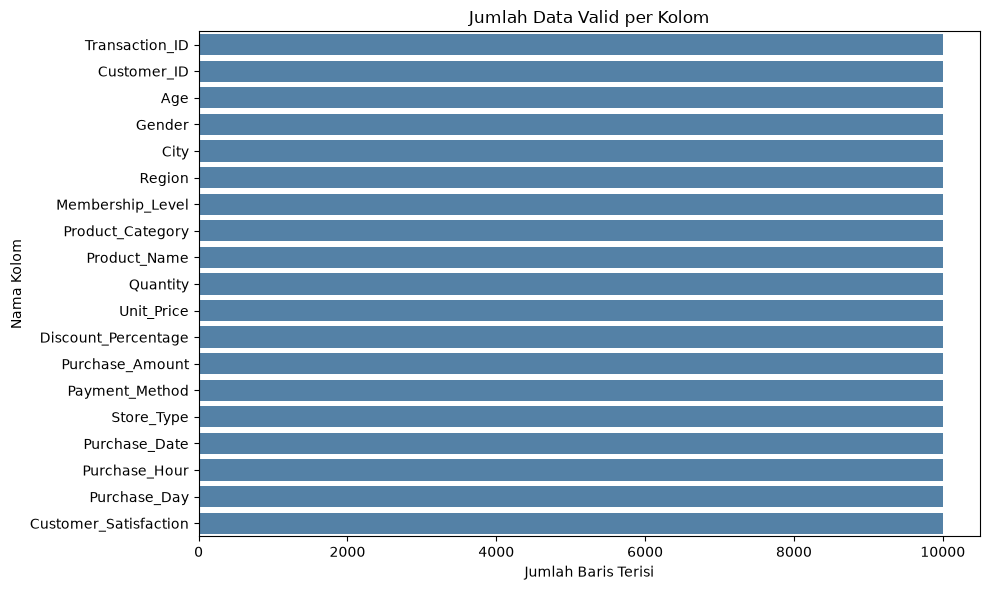

In [6]:
# Diagram jumlah data valid per kolom
plt.figure(figsize=(10, 6))
sns.barplot(x=df.notnull().sum().values, y=df.columns, color='steelblue')
plt.title('Jumlah Data Valid per Kolom')
plt.xlabel('Jumlah Baris Terisi')
plt.ylabel('Nama Kolom')
plt.tight_layout()
plt.show()

### 2. Pembuktian Duplikasi Data

In [7]:
# Jumlah baris duplikat identik pada seluruh 19 kolom
df.duplicated().sum()

np.int64(0)

In [8]:
# Duplikasi Transaction_ID, isi transaksi tanpa ID, dan jumlah Customer_ID unik
print("Duplikat Transaction_ID                  :", df['Transaction_ID'].duplicated().sum())

kolom_non_id = [col for col in df.columns if col != 'Transaction_ID']
print("Duplikat transaksi (tanpa Transaction_ID):", df.duplicated(subset=kolom_non_id).sum())

print("Total baris transaksi                    :", len(df))
print("Jumlah Customer_ID unik                  :", df['Customer_ID'].nunique())

Duplikat Transaction_ID                  : 0
Duplikat transaksi (tanpa Transaction_ID): 0
Total baris transaksi                    : 10000
Jumlah Customer_ID unik                  : 2876


### 3. Pembuktian Konsistensi Perhitungan Matematis (`Purchase_Amount`)

In [9]:
# Validasi rumus Purchase_Amount terhadap Quantity, Unit_Price, dan Discount_Percentage
gross = df['Quantity'] * df['Unit_Price']
expected_amount = gross - (gross * df['Discount_Percentage'] / 100)
selisih = (df['Purchase_Amount'] - expected_amount).abs()

print("Jumlah baris tidak konsisten (selisih > 0.01):", (selisih > 0.01).sum())
print("Selisih maksimum (Rp)                        :", selisih.max())

cek_math = df[['Transaction_ID', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Purchase_Amount']].head().copy()
cek_math['Expected_Amount'] = expected_amount.head()
cek_math['Selisih'] = selisih.head()
cek_math

Jumlah baris tidak konsisten (selisih > 0.01): 0
Selisih maksimum (Rp)                        : 0.0


,Transaction_ID,Quantity,Unit_Price,Discount_Percentage,Purchase_Amount,Expected_Amount,Selisih
0,TRX-000001,5,104000.0,0.0,520000.0,520000.0,0.0
1,TRX-000002,2,304000.0,20.0,486400.0,486400.0,0.0
2,TRX-000003,2,427000.0,10.0,768600.0,768600.0,0.0
3,TRX-000004,3,426000.0,5.0,1214100.0,1214100.0,0.0
4,TRX-000005,3,92000.0,5.0,262200.0,262200.0,0.0


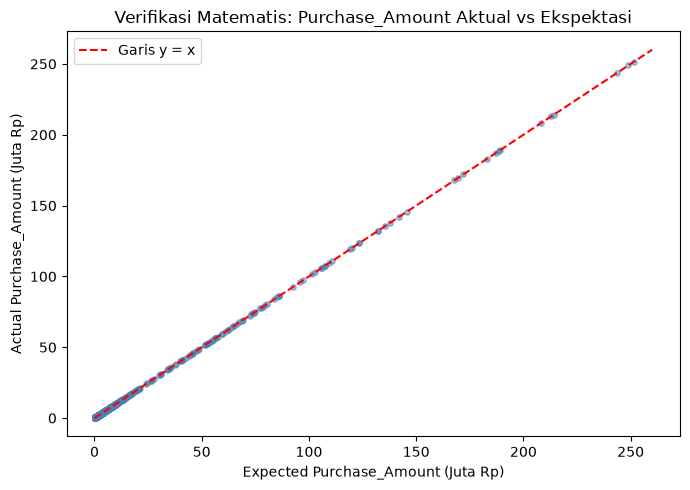

In [10]:
# Scatter plot Purchase_Amount aktual vs ekspektasi
plt.figure(figsize=(7, 5))
plt.scatter(expected_amount / 1e6, df['Purchase_Amount'] / 1e6, alpha=0.5, s=15, color='steelblue')
plt.plot([0, 260], [0, 260], color='red', linestyle='--', label='Garis y = x')
plt.title('Verifikasi Matematis: Purchase_Amount Aktual vs Ekspektasi')
plt.xlabel('Expected Purchase_Amount (Juta Rp)')
plt.ylabel('Actual Purchase_Amount (Juta Rp)')
plt.legend()
plt.tight_layout()
plt.show()

### 4. Audit Tipe Data, Konsistensi Relasional, dan Anomali Operasional

In [11]:
# Konsistensi tanggal Purchase_Date terhadap Purchase_Day
tgl = pd.to_datetime(df['Purchase_Date'])
print("Format tanggal tidak valid    :", tgl.isnull().sum())
print("Mismatch Purchase_Day         :", (tgl.dt.day_name() != df['Purchase_Day']).sum())

# Konsistensi relasi City ke Region, Product_Name ke Product_Category, dan profil Customer_ID
print("City dengan >1 Region         :", (df.groupby('City')['Region'].nunique() > 1).sum())
print("Produk dengan >1 Kategori     :", (df.groupby('Product_Name')['Product_Category'].nunique() > 1).sum())
profil_cols = ['Age', 'Gender', 'City', 'Region', 'Membership_Level']
print("Konflik profil per Customer_ID:", int((df.groupby('Customer_ID')[profil_cols].nunique() > 1).sum().sum()))

# Pengecekan tipe penyimpanan kolom pada CSV asli
print("\nKetidaksesuaian tipe penyimpanan CSV:")
print("1. Purchase_Date dtype          :", df['Purchase_Date'].dtype, "(tersimpan sebagai teks, belum datetime)")
print("2. Unit_Price nilai pecahan     :", (df['Unit_Price'] % 1 != 0).sum(), "| dtype:", df['Unit_Price'].dtype)
print("3. Discount_Percentage pecahan  :", (df['Discount_Percentage'] % 1 != 0).sum(), "| dtype:", df['Discount_Percentage'].dtype)
print("4. Purchase_Amount pecahan      :", (df['Purchase_Amount'] % 1 != 0).sum(), "| dtype:", df['Purchase_Amount'].dtype)

Format tanggal tidak valid    : 0
Mismatch Purchase_Day         : 0
City dengan >1 Region         : 0
Produk dengan >1 Kategori     : 0
Konflik profil per Customer_ID: 0

Ketidaksesuaian tipe penyimpanan CSV:
1. Purchase_Date dtype          : str (tersimpan sebagai teks, belum datetime)
2. Unit_Price nilai pecahan     : 0 | dtype: float64
3. Discount_Percentage pecahan  : 0 | dtype: float64
4. Purchase_Amount pecahan      : 0 | dtype: float64


In [12]:
# Identifikasi anomali operasional gerai fisik (Cash pada kanal daring dipertahankan karena valid sebagai COD)
m_online_cash = df['Store_Type'].isin(['Online App', 'Official Web']) & (df['Payment_Method'] == 'Cash')
m_phys_night = df['Store_Type'].isin(['Flagship Store', 'Mall Outlet']) & ((df['Purchase_Hour'] < 8) | (df['Purchase_Hour'] >= 23))

phys_df = df[df['Store_Type'].isin(['Flagship Store', 'Mall Outlet'])]
konflik_keys = phys_df.groupby(['Customer_ID', 'Purchase_Date', 'Purchase_Hour'])['Store_Type'].nunique()
bad_keys = konflik_keys[konflik_keys > 1].index
m_phys_conflict = df.set_index(['Customer_ID', 'Purchase_Date', 'Purchase_Hour']).index.isin(bad_keys) & df['Store_Type'].isin(['Flagship Store', 'Mall Outlet'])

total_anomali = (m_phys_night | m_phys_conflict).sum()

print("Catatan Cash pada kanal daring (valid COD, dipertahankan)       :", int(m_online_cash.sum()), "baris")
print("1. Gerai fisik di luar jam operasional (00:00 s.d. 07:00 & 23:00):", int(m_phys_night.sum()), "baris")
print("2. Customer_ID sama di 2 gerai fisik pada tanggal & jam sama     :", int(m_phys_conflict.sum()), "baris")
print("Total baris anomali (dipisahkan ke Data_Dikeluarkan)             :", int(total_anomali), "baris")
print("Total baris bersih (Data_Bersih)                                 :", len(df) - int(total_anomali), "baris")

# Distribusi usia batas atas (Age 60 s.d. 65)
print("\nDistribusi usia batas atas (Age 60 s.d. 65):")
df['Age'].value_counts().sort_index().loc[60:65]

Catatan Cash pada kanal daring (valid COD, dipertahankan)       : 349 baris
1. Gerai fisik di luar jam operasional (00:00 s.d. 07:00 & 23:00): 437 baris
2. Customer_ID sama di 2 gerai fisik pada tanggal & jam sama     : 6 baris
Total baris anomali (dipisahkan ke Data_Dikeluarkan)             : 443 baris
Total baris bersih (Data_Bersih)                                 : 9557 baris

Distribusi usia batas atas (Age 60 s.d. 65):


Age
60     35
61     43
62     21
63     17
64     10
65    100
Name: count, dtype: int64

## Bagian A.3: Analisis Tingkat Pelanggan vs. Tingkat Transaksi

Perbandingan rata rata `Age` dan persentase `Gender` pada **10.000 baris transaksi** vs. **2.876 pelanggan unik (`Customer_ID`)** (tabel deskriptif dan histogram Excel tersedia di sheet `A3_Analisis_Deskriptif` pada `TugasBagianA_Kelompok.xlsx`).

In [13]:
# Deduplikasi pelanggan unik berdasarkan Customer_ID
df_pelanggan = df.drop_duplicates(subset=['Customer_ID']).copy()

print("Total Transaksi      :", len(df))
print("Total Pelanggan Unik :", len(df_pelanggan))
print("Rata rata Trx/Cust   :", round(len(df) / len(df_pelanggan), 2))

# Perbandingan statistik Age
print("\n=== Perbandingan Usia (Age) ===")
print(f"Tingkat Transaksi      : Mean = {df['Age'].mean():.2f}, Median = {df['Age'].median():.2f}, Mode = {df['Age'].mode()[0]}, Std = {df['Age'].std():.2f}")
print(f"Tingkat Pelanggan Unik : Mean = {df_pelanggan['Age'].mean():.2f}, Median = {df_pelanggan['Age'].median():.2f}, Mode = {df_pelanggan['Age'].mode()[0]}, Std = {df_pelanggan['Age'].std():.2f}")

# Perbandingan distribusi Gender (%)
gender_trx = df['Gender'].value_counts(normalize=True) * 100
gender_cust = df_pelanggan['Gender'].value_counts(normalize=True) * 100

tabel_gender = pd.DataFrame({
    'Transaksi_Count': df['Gender'].value_counts(),
    'Transaksi_%': gender_trx.round(2),
    'Pelanggan_Unik_Count': df_pelanggan['Gender'].value_counts(),
    'Pelanggan_Unik_%': gender_cust.round(2),
})
tabel_gender

Total Transaksi      : 10000
Total Pelanggan Unik : 2876
Rata rata Trx/Cust   : 3.48

=== Perbandingan Usia (Age) ===
Tingkat Transaksi      : Mean = 36.91, Median = 35.00, Mode = 32, Std = 8.85
Tingkat Pelanggan Unik : Mean = 36.96, Median = 36.00, Mode = 35, Std = 8.89


,Transaksi_Count,Transaksi_%,Pelanggan_Unik_Count,Pelanggan_Unik_%
Gender,,,,
Female,4951,49.51,1463,50.87
Male,5049,50.49,1413,49.13


In [14]:
# Frekuensi transaksi per pelanggan berdasarkan Gender dan Top 5 pelanggan teraktif
freq_cust = df.groupby(['Customer_ID', 'Age', 'Gender']).size().reset_index(name='Jumlah_Transaksi')

print("Rata rata frekuensi transaksi per pelanggan berdasarkan Gender:")
print(freq_cust.groupby('Gender')['Jumlah_Transaksi'].mean().round(2))

freq_cust.sort_values('Jumlah_Transaksi', ascending=False).head(5)

Rata rata frekuensi transaksi per pelanggan berdasarkan Gender:
Gender
Female    3.38
Male      3.57
Name: Jumlah_Transaksi, dtype: float64


,Customer_ID,Age,Gender,Jumlah_Transaksi
607,CUST-00679,32,Male,137
1319,CUST-01469,34,Male,69
889,CUST-00983,32,Female,38
1307,CUST-01454,46,Female,35
2016,CUST-02237,41,Male,32


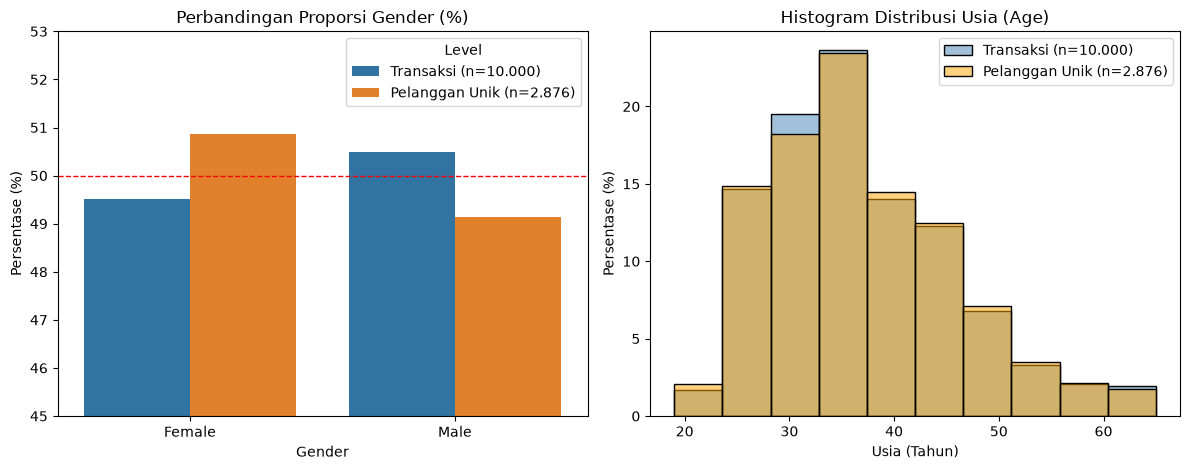

In [15]:
# Diagram perbandingan proporsi Gender dan histogram distribusi Age
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Diagram proporsi Gender (%)
plot_gender = pd.DataFrame({
    'Gender': ['Female', 'Male', 'Female', 'Male'],
    'Persentase': [gender_trx['Female'], gender_trx['Male'], gender_cust['Female'], gender_cust['Male']],
    'Level': ['Transaksi (n=10.000)', 'Transaksi (n=10.000)', 'Pelanggan Unik (n=2.876)', 'Pelanggan Unik (n=2.876)']
})
sns.barplot(data=plot_gender, x='Gender', y='Persentase', hue='Level', ax=axes[0])
axes[0].axhline(50, color='red', linestyle='--', linewidth=1)
axes[0].set_ylim(45, 53)
axes[0].set_title('Perbandingan Proporsi Gender (%)')
axes[0].set_ylabel('Persentase (%)')

# Histogram distribusi Age
sns.histplot(df['Age'], stat='percent', bins=10, color='steelblue', alpha=0.5, label='Transaksi (n=10.000)', ax=axes[1])
sns.histplot(df_pelanggan['Age'], stat='percent', bins=10, color='orange', alpha=0.5, label='Pelanggan Unik (n=2.876)', ax=axes[1])
axes[1].set_title('Histogram Distribusi Usia (Age)')
axes[1].set_xlabel('Usia (Tahun)')
axes[1].set_ylabel('Persentase (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

## Kesimpulan Bagian A
1. **A.1 (Klasifikasi Variabel):** Seluruh 19 kolom terklasifikasi sesuai deskripsi dataset ke 6 tipe statistik (`Identifier`: 2, `Nominal`: 7, `Ordinal`: 3, `Diskrit`: 3, `Kontinu`: 3, `Temporal`: 1) dan dikelompokkan dalam sheet terpisah pada `TugasBagianA_Kelompok.xlsx`.
2. **A.2 (Audit Kualitas Data):** Secara struktural dataset memiliki `0` missing value (`isnull().sum()`), `0` baris duplikat (`duplicated().sum()`), `0` duplikat `Transaction_ID`, dan `0` inkonsistensi rumus matematis `Purchase_Amount`. Transaksi `Cash` pada kanal daring (`349` baris) tetap dipertahankan karena valid sebagai COD (*Cash on Delivery*). Perbaikan pada `TugasBagianA_Bersih.xlsx` mencakup standardisasi tipe penyimpanan CSV (`Purchase_Date` ke format tanggal asli, angka `.0` ke bilangan bulat) serta pemisahan **443 baris anomali operasional gerai fisik** (`437` transaksi gerai fisik pada jam `00:00` s.d. `07:00` dan `23:00`, serta `6` baris konflik 2 gerai fisik berbeda pada tanggal dan jam yang sama), menghasilkan **9.557 baris data bersih**.
3. **A.3 (Pelanggan Unik vs. Transaksi):** Perbedaan hasil disebabkan oleh pembobotan frekuensi transaksi ulang (`2.876` pelanggan unik menghasilkan `10.000` transaksi, rata rata `3,48` transaksi/pelanggan, maksimum `137` transaksi). Pada tingkat transaksi, mayoritas Gender tampak **Male (50,49%)** dan modus usia bergeser ke **32 tahun**, padahal pada tingkat pelanggan unik mayoritas sebenarnya adalah **Female (50,87%)** dengan rata rata usia **36,96 tahun** (median 36, modus 35). Metrik yang lebih valid untuk menggambarkan profil demografi pelanggan adalah **tingkat pelanggan unik (`n = 2.876`)**.